# ЛР1, ч.1 - библиотеки, первичный анализ, визуализация, нормализация
Основной датасет - Iris, для нормализации ещё Wine.

# Краткий обзор основных библиотек:

NumPy:
- Базовая библиотека для научных вычислений в Python.  
- Предоставляет многомерный массив ndarray, векторизованные операции, линалг, генераторы случайных чисел.  

Pandas:
- Высокоуровневая библиотека для работы с табличными данными (DataFrame, Series).  
- Удобная загрузка/сохранение данных, фильтрация, группировка, агрегация, работа с временными рядами.  

Scikit‑learn:
- Набор алгоритмов машинного обучения (классификация, регрессия, кластеризация, понижение размерности и т. д.).  
- Единый API: .fit(), .transform(), .fit_predict(), интеграция с пайплайнами.  

umap-learn (UMAP):
- Алгоритм понижения размерности и manifold‑обучения (Uniform Manifold Approximation and Projection).  
- Хорошо подходит для визуализации высокоразмерных данных и как этап препроцессинга перед кластеризацией.  


## Установка

In [1]:
%pip install -q numpy pandas scikit-learn matplotlib seaborn ipywidgets
%pip install -q umap-learn

Note: you may need to restart the kernel to use updated packages.


Note: you may need to restart the kernel to use updated packages.


In [2]:
# ===== Импорт библиотек =====
import numpy as np
import pandas as pd
from sklearn.datasets import load_iris, load_wine  # встроенные датасеты
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')  # скрываем технические предупреждения библиотек

pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 20)

Z-оценка через broadcasting и циклом:

In [3]:
import time

rng = np.random.default_rng(42)
X_demo = rng.normal(loc=[0, 10, 100], scale=[1, 5, 50], size=(100_000, 3))

# Векторизованно: одна строка, broadcasting вектора средних и СКО на все строки
t0 = time.perf_counter()
Z_vec = (X_demo - X_demo.mean(axis=0)) / X_demo.std(axis=0)
t_vec = time.perf_counter() - t0

# То же самое циклом по элементам
t0 = time.perf_counter()
mu, sd = X_demo.mean(axis=0), X_demo.std(axis=0)
Z_loop = np.empty_like(X_demo)
for i in range(X_demo.shape[0]):
    for j in range(X_demo.shape[1]):
        Z_loop[i, j] = (X_demo[i, j] - mu[j]) / sd[j]
t_loop = time.perf_counter() - t0

print(f"Результаты совпадают: {np.allclose(Z_vec, Z_loop)}")
print(f"Векторизация: {t_vec*1000:.1f} мс, цикл: {t_loop*1000:.0f} мс (быстрее в {t_loop/t_vec:.0f} раз)")
print("Средние после стандартизации:", Z_vec.mean(axis=0).round(6))
print("СКО после стандартизации:   ", Z_vec.std(axis=0).round(6))

Результаты совпадают: True
Векторизация: 4.5 мс, цикл: 127 мс (быстрее в 28 раз)
Средние после стандартизации: [-0.  0.  0.]
СКО после стандартизации:    [1. 1. 1.]


Результат одинаковый, векторизация быстрее в десятки раз.

## Загрузка Iris

In [4]:
# ===== Загрузка датасета Iris =====
iris_bunch = load_iris()  # sklearn.utils.Bunch с полями data, target, feature_names и т. д. 

# Преобразуем в pandas.DataFrame
df = pd.DataFrame(
    data=iris_bunch.data,
    columns=iris_bunch.feature_names
)  # стандартный способ перевода датасета sklearn в DataFrame. [web:4][web:9]

# Добавим столбец с целевым классом в виде чисел и текстовых меток
df["target"] = iris_bunch.target
df["target_name"] = df["target"].apply(lambda i: iris_bunch.target_names[i])  # имена видов ириса. 


## Первичный анализ

In [5]:
# ===== Первичный анализ структуры данных =====
print("Первые 5 строк:")
print(df.head())  # быстрое представление структуры табличных данных. 

print("\nИнформация о DataFrame:")
print(df.info())  # типы столбцов, количество непустых значений. 

print("\nОписательная статистика по числовым признакам:")
print(df.describe())  # среднее, стандартное отклонение, квартили и т. д.

print("\nРаспределение классов:")
print(df["target_name"].value_counts())  # баланс классов для задачи классификации. 




Первые 5 строк:
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  target target_name
0                5.1               3.5                1.4               0.2       0      setosa
1                4.9               3.0                1.4               0.2       0      setosa
2                4.7               3.2                1.3               0.2       0      setosa
3                4.6               3.1                1.5               0.2       0      setosa
4                5.0               3.6                1.4               0.2       0      setosa

Информация о DataFrame:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null   

In [6]:
features = iris_bunch.feature_names

print("Пропуски по столбцам:\n", df.isna().sum(), sep='')
dup_mask = df.duplicated(subset=features, keep=False)
print(f"\nПолных дубликатов по признакам: {df.duplicated(subset=features).sum()}")
print(df[dup_mask])

print("\nКоэффициент вариации (СКО / среднее) — относительный разброс признаков:")
print((df[features].std() / df[features].mean()).round(3))

print("\nСредние значения признаков по классам:")
print(df.groupby("target_name")[features].agg(['mean', 'std']).round(2).T)

Пропуски по столбцам:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
target               0
target_name          0
dtype: int64

Полных дубликатов по признакам: 1
     sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  target target_name
101                5.8               2.7                5.1               1.9       2   virginica
142                5.8               2.7                5.1               1.9       2   virginica

Коэффициент вариации (СКО / среднее) — относительный разброс признаков:
sepal length (cm)    0.142
sepal width (cm)     0.143
petal length (cm)    0.470
petal width (cm)     0.636
dtype: float64

Средние значения признаков по классам:
target_name             setosa  versicolor  virginica
sepal length (cm) mean    5.01        5.94       6.59
                  std     0.35        0.52       0.64
sepal width (cm)  mean    3.43        2.77       2.97
                  std     0.38        0.31    

- 150 объектов, 4 признака, пропусков нет, классы 50/50/50.
- Один дубликат (строки 101 и 142).
- Setosa сильно отличается маленькими лепестками, versicolor и virginica ближе друг к другу.

## Визуализация

In [7]:
# ===== Простые визуализации =====
sns.set(style="whitegrid")

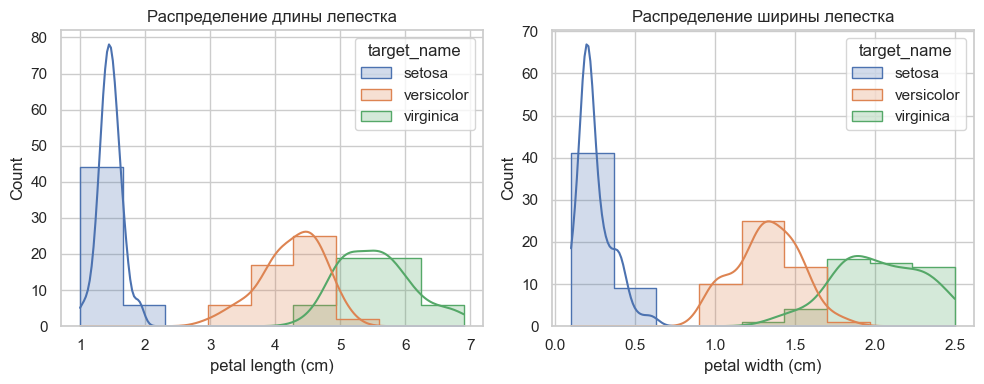

In [8]:
# Диаграммы распределения длины и ширины лепестка по классам
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
sns.histplot(
    data=df,
    x="petal length (cm)",
    hue="target_name",
    kde=True,
    element="step"
)
plt.title("Распределение длины лепестка")

plt.subplot(1, 2, 2)
sns.histplot(
    data=df,
    x="petal width (cm)",
    hue="target_name",
    kde=True,
    element="step"
)
plt.title("Распределение ширины лепестка")
plt.tight_layout()
plt.show()

Признаки лепестка отделяют setosa, versicolor/virginica частично перекрываются.

### Pairplot

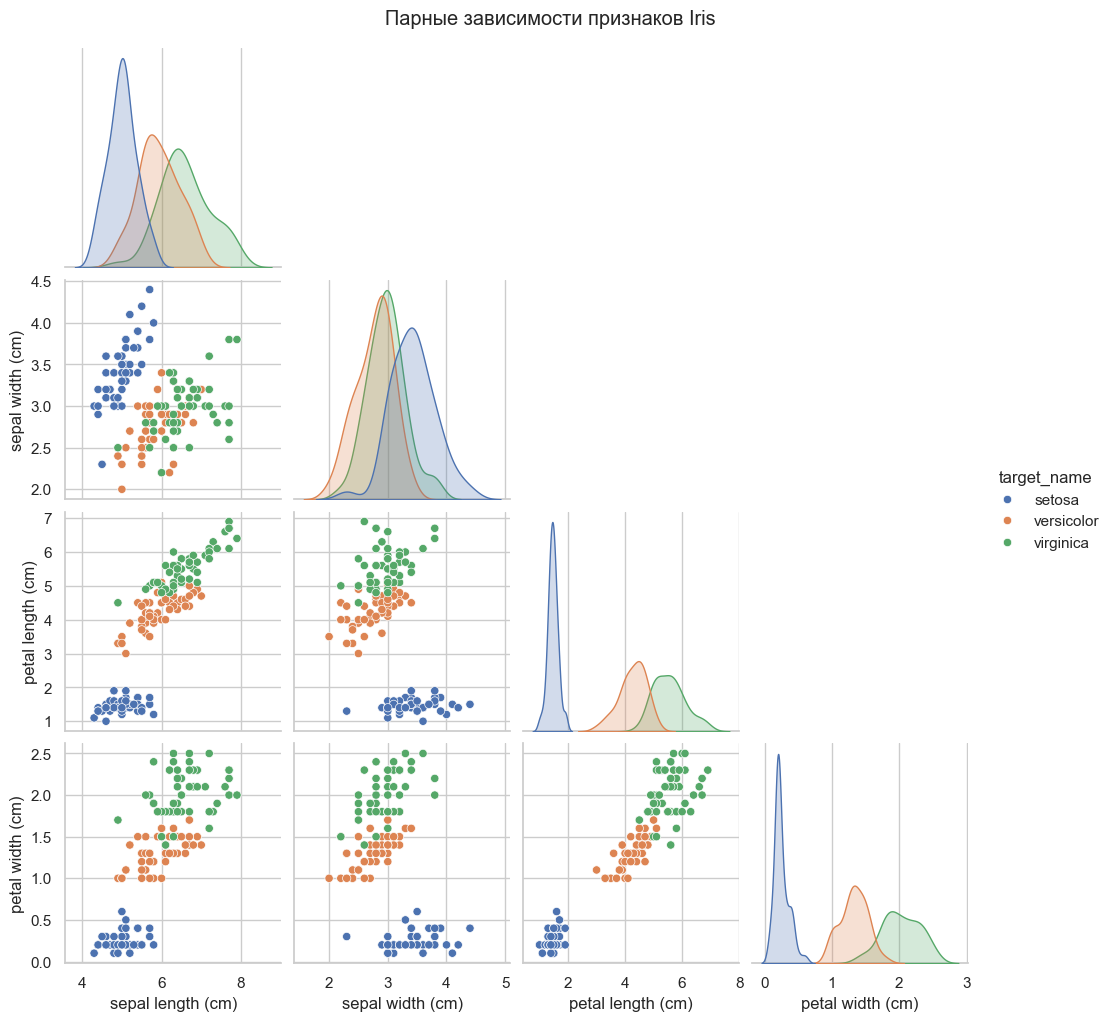

In [9]:
# Парные диаграммы признаков
sns.pairplot(
    df,
    vars=iris_bunch.feature_names,
    hue="target_name",
    corner=True
)
plt.suptitle("Парные зависимости признаков Iris", y=1.02)
plt.show()

На парах с лепестками классы видны, ширина чашелистика почти ничего не даёт.

### Boxplot

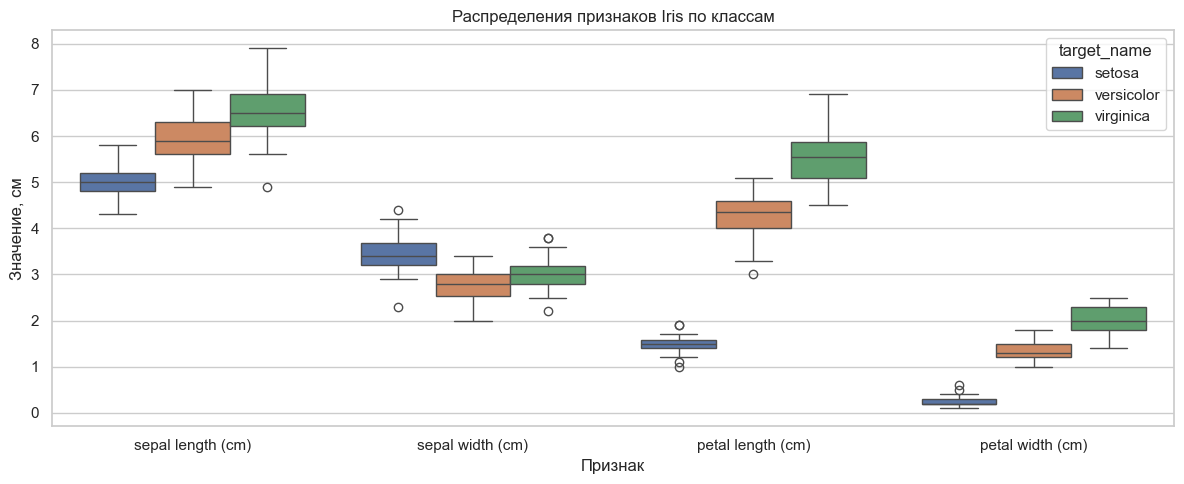

In [10]:
df_long = df.melt(id_vars="target_name", value_vars=features,
                  var_name="Признак", value_name="Значение, см")
plt.figure(figsize=(12, 5))
sns.boxplot(data=df_long, x="Признак", y="Значение, см", hue="target_name")
plt.title("Распределения признаков Iris по классам")
plt.tight_layout()
plt.show()

### Корреляции: вся выборка и отдельно по классам

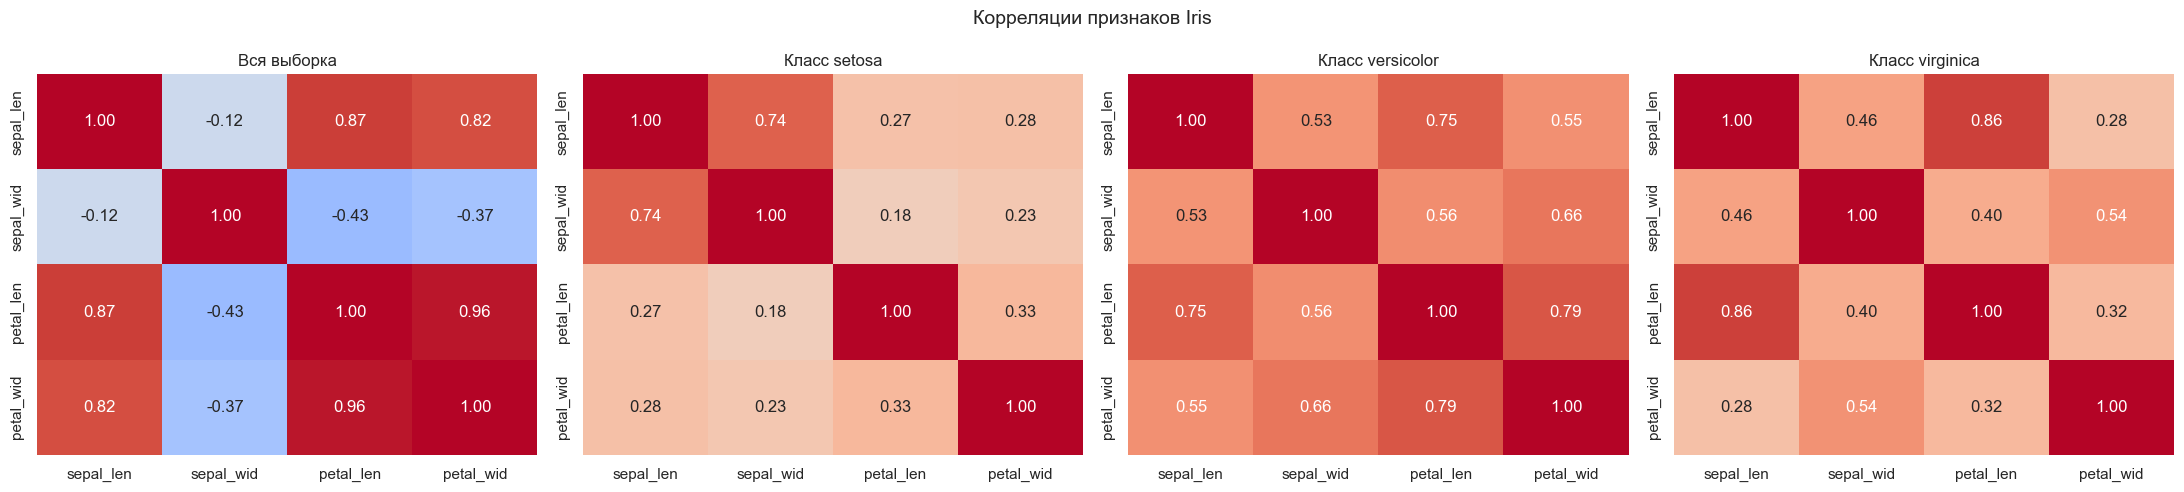

In [11]:
fig, axes = plt.subplots(1, 4, figsize=(22, 5))
short = ["sepal_len", "sepal_wid", "petal_len", "petal_wid"]

corr_all = df[features].corr()
sns.heatmap(corr_all, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1,
            xticklabels=short, yticklabels=short, ax=axes[0], cbar=False)
axes[0].set_title("Вся выборка")

for ax, name in zip(axes[1:], iris_bunch.target_names):
    sns.heatmap(df.loc[df.target_name == name, features].corr(), annot=True, fmt=".2f",
                cmap="coolwarm", vmin=-1, vmax=1, xticklabels=short, yticklabels=short,
                ax=ax, cbar=False)
    ax.set_title(f"Класс {name}")
plt.suptitle("Корреляции признаков Iris", fontsize=14)
plt.tight_layout()
plt.show()

- petal length / petal width: r ≈ 0.96 - признаки избыточны.
- sepal length / sepal width: по всей выборке r ≈ −0.12, внутри каждого класса - положительная (парадокс Симпсона).

### Clustermap

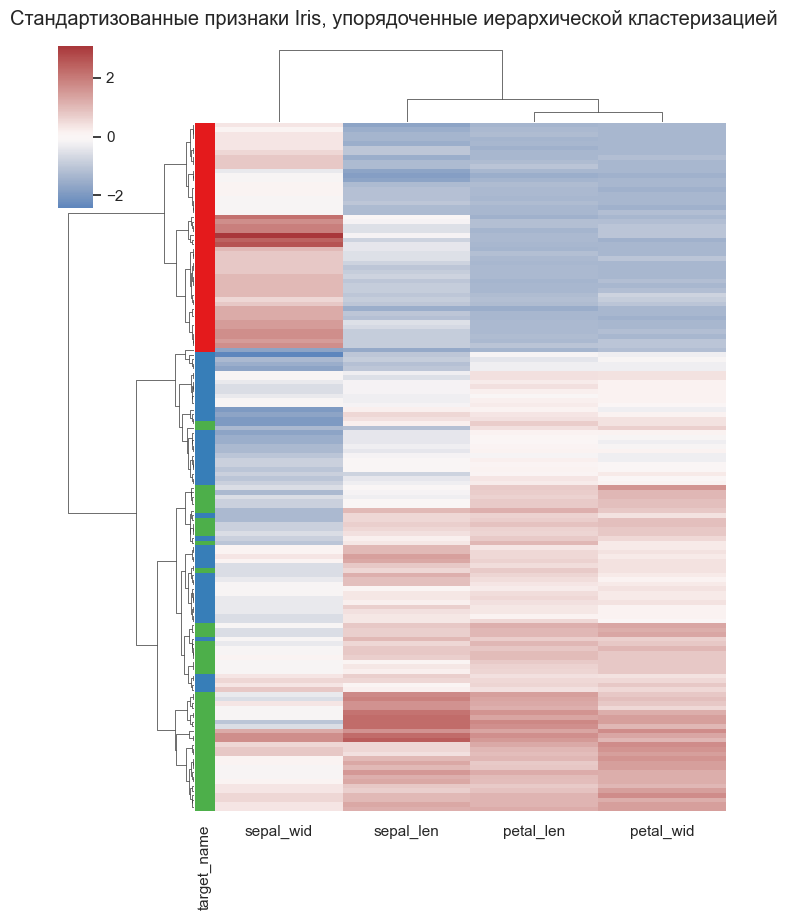

In [12]:
from sklearn.preprocessing import StandardScaler

Z = pd.DataFrame(StandardScaler().fit_transform(df[features]), columns=short)
lut = dict(zip(iris_bunch.target_names, sns.color_palette("Set1", 3)))
row_colors = df["target_name"].map(lut)

g = sns.clustermap(Z, method="ward", cmap="vlag", center=0, row_colors=row_colors,
                   figsize=(7, 9), yticklabels=False, dendrogram_ratio=(0.2, 0.1))
g.fig.suptitle("Стандартизованные признаки Iris, упорядоченные иерархической кластеризацией", y=1.02)
plt.show()

Дендрограмма первым же разрезом отделяет setosa, versicolor/virginica перемешаны.

## Нормализация
Сравниваю StandardScaler / MinMaxScaler / RobustScaler. 

In [13]:
from sklearn.preprocessing import StandardScaler 

X = iris_bunch.data       # признаки (4 числовых признака).  
y = iris_bunch.target     # классы (0, 1, 2). 

# 2. Стандартизация признаков: (x - mean) / std.  
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)  # возвращает numpy-массив того же размера.  

In [14]:
print("До масштабирования:    mean =", X.mean(axis=0).round(2), " std =", X.std(axis=0).round(2))
print("После масштабирования: mean =", X_scaled.mean(axis=0).round(2), " std =", X_scaled.std(axis=0).round(2))
print("Сохранённые параметры scaler: mean_ =", scaler.mean_.round(2), " scale_ =", scaler.scale_.round(2))

До масштабирования:    mean = [5.84 3.06 3.76 1.2 ]  std = [0.83 0.43 1.76 0.76]
После масштабирования: mean = [-0. -0. -0. -0.]  std = [1. 1. 1. 1.]
Сохранённые параметры scaler: mean_ = [5.84 3.06 3.76 1.2 ]  scale_ = [0.83 0.43 1.76 0.76]


### Wine: признаки в разных единицах

                                mean     std     min      max
alcohol                        13.00    0.81   11.03    14.83
malic_acid                      2.34    1.12    0.74     5.80
ash                             2.37    0.27    1.36     3.23
alcalinity_of_ash              19.49    3.34   10.60    30.00
magnesium                      99.74   14.28   70.00   162.00
total_phenols                   2.30    0.63    0.98     3.88
flavanoids                      2.03    1.00    0.34     5.08
nonflavanoid_phenols            0.36    0.12    0.13     0.66
proanthocyanins                 1.59    0.57    0.41     3.58
color_intensity                 5.06    2.32    1.28    13.00
hue                             0.96    0.23    0.48     1.71
od280/od315_of_diluted_wines    2.61    0.71    1.27     4.00
proline                       746.89  314.91  278.00  1680.00


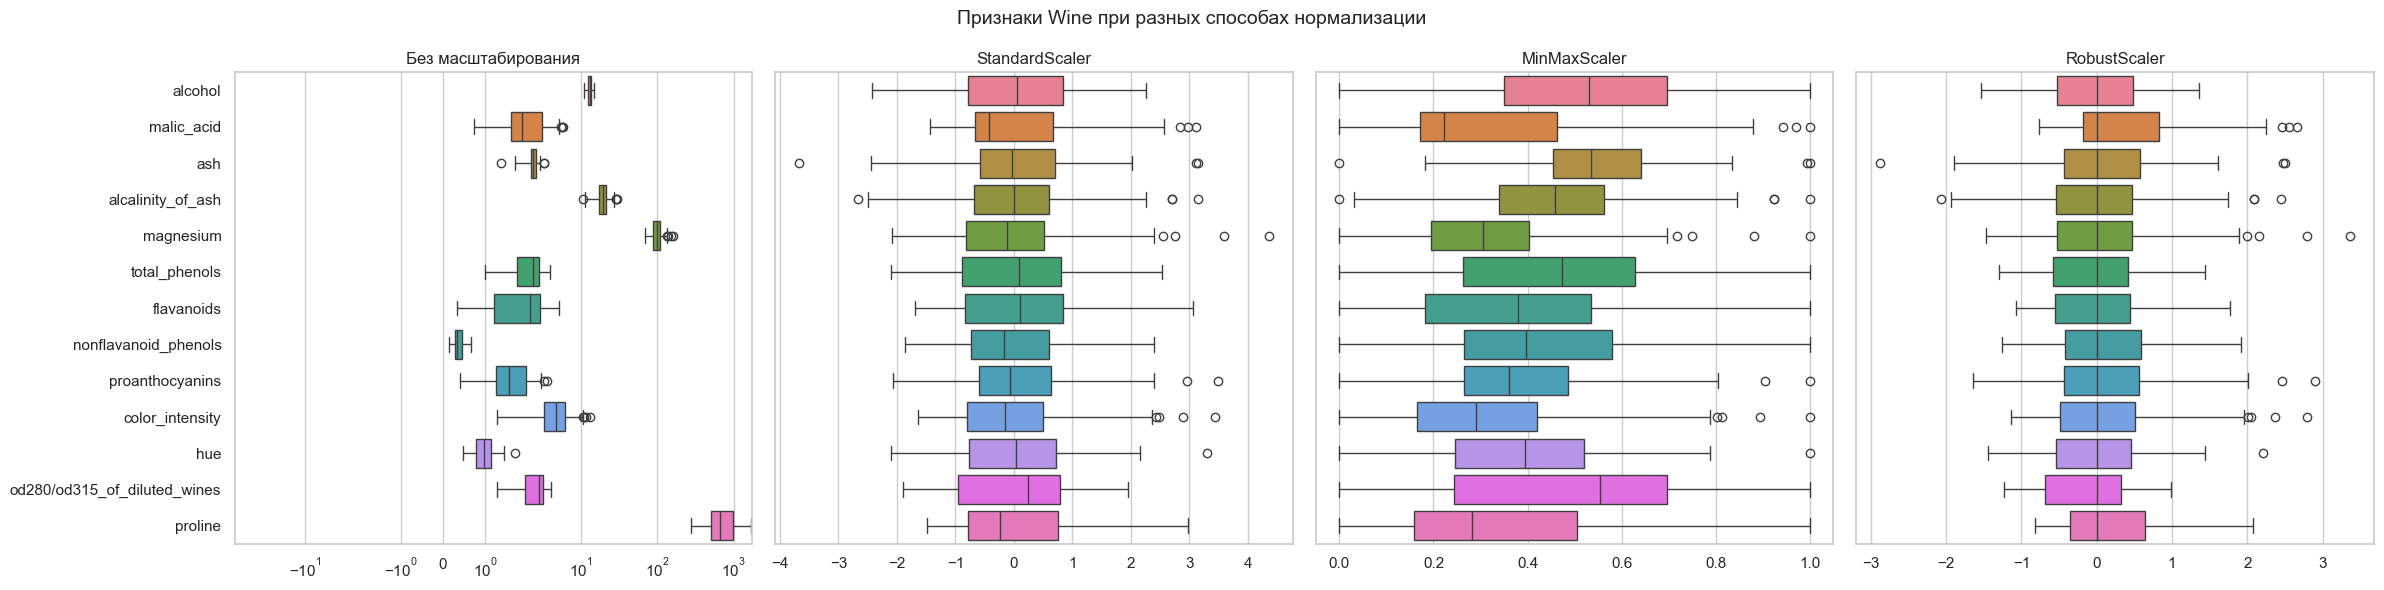

In [15]:
from sklearn.preprocessing import MinMaxScaler, RobustScaler

wine = load_wine()
Xw, yw = wine.data, wine.target
wine_df = pd.DataFrame(Xw, columns=wine.feature_names)
print(wine_df.describe().T[["mean", "std", "min", "max"]].round(2))

scalers = {"Без масштабирования": None, "StandardScaler": StandardScaler(),
           "MinMaxScaler": MinMaxScaler(), "RobustScaler": RobustScaler()}
fig, axes = plt.subplots(1, 4, figsize=(24, 6), sharey=True)
for ax, (name, sc) in zip(axes, scalers.items()):
    data = wine_df if sc is None else pd.DataFrame(sc.fit_transform(Xw), columns=wine.feature_names)
    sns.boxplot(data=data, orient="h", ax=ax)
    ax.set_title(name)
axes[0].set_xscale("symlog")
plt.suptitle("Признаки Wine при разных способах нормализации", fontsize=14)
plt.tight_layout()
plt.show()

Без масштабирования признаки отличаются на 3 порядка. Проверяю, как это влияет на KMeans (ARI):

In [16]:
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score

rows = []
for ds_name, Xd, yd in [("Iris", X, y), ("Wine", Xw, yw)]:
    for sc_name, sc in scalers.items():
        Xs = Xd if sc is None else sc.fit_transform(Xd)
        labels = KMeans(n_clusters=3, n_init=10, random_state=42).fit_predict(Xs)
        rows.append({"Датасет": ds_name, "Нормализация": sc_name,
                     "ARI": adjusted_rand_score(yd, labels)})
ari_table = pd.DataFrame(rows).pivot(index="Нормализация", columns="Датасет", values="ARI")
print(ari_table.round(3))

Датасет               Iris   Wine
Нормализация                     
MinMaxScaler         0.716  0.854
RobustScaler         0.580  0.895
StandardScaler       0.620  0.897
Без масштабирования  0.730  0.371


- Wine: без масштабирования ARI ≈ 0.37, со StandardScaler ≈ 0.90 - масштабировать обязательно.
- Iris: наоборот, на сырых данных лучше (0.73 против 0.62) - стандартизация «раздувает» шумную ширину чашелистика.

## UMAP

In [17]:
# можно закомментировать при отсутствии пакета

try:
    import umap  # pip install umap-learn  
    HAS_UMAP = True
except ImportError:
    HAS_UMAP = False

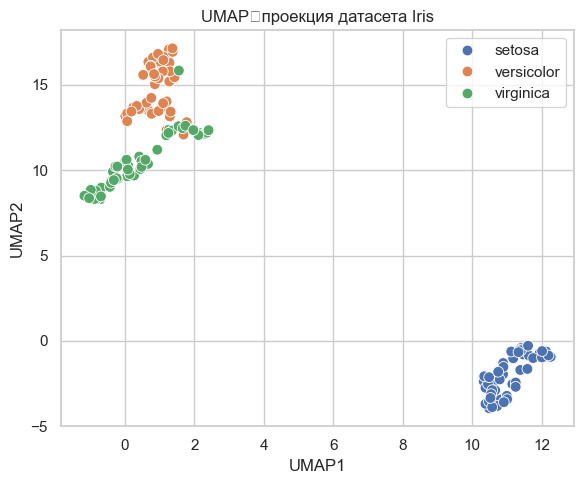

In [18]:
# ===== Пример применения UMAP (опционально) =====

if HAS_UMAP:
    reducer = umap.UMAP(random_state=42)  # UMAP как общий алгоритм понижения размерности.
    embedding = reducer.fit_transform(iris_bunch.data)  # проекция в 2D‑пространство. 

    umap_df = pd.DataFrame(
        embedding,
        columns=["UMAP1", "UMAP2"]
    )
    umap_df["target_name"] = df["target_name"].values

    plt.figure(figsize=(6, 5))
    sns.scatterplot(
        data=umap_df,
        x="UMAP1",
        y="UMAP2",
        hue="target_name",
        s=60
    )
    plt.title("UMAP‑проекция датасета Iris")
    plt.legend()
    plt.tight_layout()
    plt.show()
else:
    print(
        "\nUMAP не установлен. "
        "Чтобы использовать понижение размерности UMAP, установите пакет: pip install umap-learn"
    )  # UMAP распространяется как пакет umap-learn.  


Для UMAP обычно сначала масштабируют признаки, например с помощью StandardScaler из scikit‑learn, а затем уже подают их в UMAP.​

Простой пример со StandardScaler

In [19]:
import umap

# 3. UMAP на стандартизованных данных.
# random_state для воспроизводимости
umap_model = umap.UMAP(
    n_neighbors=15,
    min_dist=0.1,
    n_components=2,
    random_state=42,
)  # базовые параметры UMAP

X_umap = umap_model.fit_transform(X_scaled)  # понижение размерности до 2D

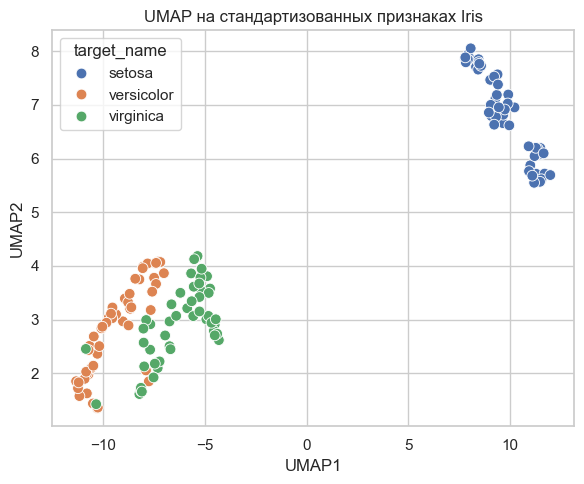

In [20]:
# 4. Визуализация результата
umap_df = pd.DataFrame(
    X_umap,
    columns=["UMAP1", "UMAP2"]
)
umap_df["target"] = y
umap_df["target_name"] = umap_df["target"].apply(lambda i: iris_bunch.target_names[i])

plt.figure(figsize=(6, 5))
sns.scatterplot(
    data=umap_df,
    x="UMAP1",
    y="UMAP2",
    hue="target_name",
    s=60
)
plt.title("UMAP на стандартизованных признаках Iris")
plt.tight_layout()
plt.show()

* Стандартизатор обучается только на матрице признаков X и сохраняет среднее и стандартное отклонение для каждого признака.
​

* В UMAP подаётся уже X_scaled, а не исходные значения, что делает метрику расстояния более корректной, когда признаки в разных шкалах.


В обоих случаях setosa отдельно, versicolor и virginica рядом.

## Разрежённые данные

UMAP умеет работать напрямую с разрежёнными матрицами, а стандартизировать их нужно аккуратно, чтобы не разрушить разрежённость.

 
UMAP принимает sparse‑матрицы (CSR/CSC) и не требует предварительного перевода их в неразреженные матрицы.
​

При стандартизации разреженных данных нельзя вычитать среднее, иначе нули превращаются в ненули и матрица перестаёт быть разрежённой.
​

Для таких случаев в StandardScaler устанавливают with_mean=False, чтобы делить только на стандартное отклонение.


`with_mean=False`, чтобы матрица осталась разрежённой; метрика `cosine`.

In [21]:
from scipy.sparse import csr_matrix, random

# Создание разреженной матрицы с заданным размером и заполнением
n_rows = 1000  # количество строк (образцов)
n_cols = 5000  # количество столбцов (признаков)
density = 0.01  # плотность (процент ненулевых элементов)

# Способ 1: Создание случайной разреженной матрицы
X_sparse = random(n_rows, n_cols, density=density, format='csr')

print(f"Разреженная матрица {n_rows}x{n_cols}")
print(f"Плотность: {density*100:.1f}%")
print(f"Количество ненулевых элементов: {X_sparse.nnz}")
print(f"Тип матрицы: {type(X_sparse)}")

Разреженная матрица 1000x5000
Плотность: 1.0%
Количество ненулевых элементов: 50000
Тип матрицы: <class 'scipy.sparse._csr.csr_matrix'>


In [22]:
dense_mb = X_sparse.shape[0] * X_sparse.shape[1] * 8 / 1024**2
sparse_mb = (X_sparse.data.nbytes + X_sparse.indices.nbytes + X_sparse.indptr.nbytes) / 1024**2
print(f"Плотное хранение: {dense_mb:.1f} МБ, CSR: {sparse_mb:.2f} МБ")

Плотное хранение: 38.1 МБ, CSR: 0.58 МБ


In [23]:
# 1. Стандартизация разрежённых данных
scaler = StandardScaler(
    with_mean=False,   # важно: не вычитать среднее для sparse
    with_std=True
)
X_scaled = scaler.fit_transform(X_sparse)  # остаётся sparse-матрицей
print("После масштабирования тип:", type(X_scaled), " ненулевых:", X_scaled.nnz)

# 2. UMAP на стандартизованных sparse-данных
umap_model = umap.UMAP(
    n_neighbors=15,
    min_dist=0.1,
    n_components=2,
    metric="cosine",   # популярная метрика для текстовых/разрежённых данных
    random_state=42,
)
X_embedded = umap_model.fit_transform(X_scaled)  # получается плотный массив (n_samples, 2)

После масштабирования тип: <class 'scipy.sparse._csr.csr_matrix'>  ненулевых: 50000


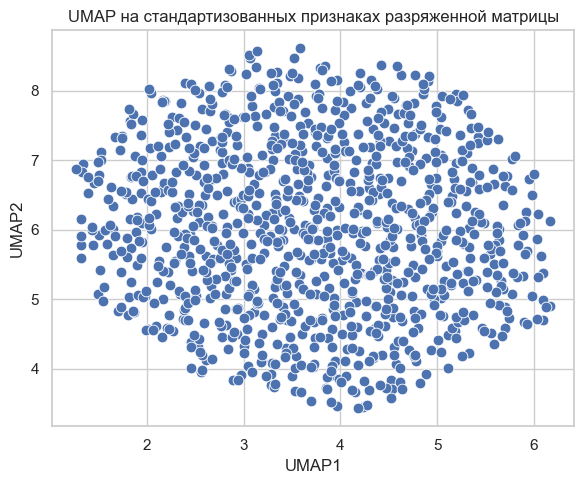

In [24]:
# 4. Визуализация результата
umap_df = pd.DataFrame(
    X_embedded,
    columns=["UMAP1", "UMAP2"]
)

plt.figure(figsize=(6, 5))
sns.scatterplot(
    data=umap_df,
    x="UMAP1",
    y="UMAP2",
    #hue="target_name",
    s=60
)
plt.title("UMAP на стандартизованных признаках разряженной матрицы")
plt.tight_layout()
plt.show()

Матрица случайная, поэтому UMAP даёт одно облако без кластеров - так и должно быть.

## Выводы
- Iris: признаки лепестка самые информативные и сильно коррелированы.
- Нормализация - это выбор метрики: для Wine обязательна, для Iris может ухудшить.
- Для разрежённых данных `with_mean=False` и косинусное расстояние.